# Finding 4: Referee Decisions and Home Advantage

Away teams received more yellow cards per foul in 2025/2026 but the difference was smaller in 2020/2021.

This analysis compares yellow cards per fould between home and away teams to investigate whether referee decisions are associated with home advantage.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl

In [7]:
epl_2025 = pd.read_csv("data/E0.csv")

print("Dataset Shape:", epl_2025.shape)

display(epl_2025[["Date", "HomeTeam", "AwayTeam", "HF", "AF", "HY", "AY"]
    ].head())

Dataset Shape: (380, 132)


,Date,HomeTeam,AwayTeam,HF,AF,HY,AY
0,15/08/2025,Liverpool,Bournemouth,7,10,1,2
1,16/08/2025,Aston Villa,Newcastle,13,11,1,1
2,16/08/2025,Brighton,Fulham,16,15,3,3
3,16/08/2025,Sunderland,West Ham,8,10,0,1
4,16/08/2025,Tottenham,Burnley,14,8,0,0


In [8]:
# Step 6: Filter completed matches for the 2025/2026 season

epl_2025_completed = epl_2025.dropna(
    subset=["FTHG", "FTAG", "HF", "AF", "HY", "AY"]
).copy()

print("Total scheduled matches:", len(epl_2025))
print("Completed matches:", len(epl_2025_completed))

print("Total home fouls:", epl_2025_completed["HF"].sum())
print("Total away fouls:", epl_2025_completed["AF"].sum())

Total scheduled matches: 380
Completed matches: 380
Total home fouls: 4048
Total away fouls: 4176


# Data Validation

We checked the match dates and missing values to verify that the dataset contains completed matches from the 2025/2026 season.

In [9]:
# Check the data range and match results

epl_2025["Date"] = pd.to_datetime(epl_2025["Date"],
                                  dayfirst=True,
                                  errors="coerce"
                                 )

print("Earliest match:", epl_2025["Date"].min())
print("Latest match:", epl_2025["Date"].max())

print("Missing match dates:", epl_2025["Date"].isna().sum())
print("Missing results:", epl_2025["FTHG"].isna().sum())

display(epl_2025[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]].tail())

Earliest match: 2025-08-15 00:00:00
Latest match: 2026-05-24 00:00:00
Missing match dates: 0
Missing results: 0


,Date,HomeTeam,AwayTeam,FTHG,FTAG
375,2026-05-24,Man City,Aston Villa,1,2
376,2026-05-24,Nott'm Forest,Bournemouth,1,1
377,2026-05-24,Sunderland,Chelsea,2,1
378,2026-05-24,Tottenham,Everton,1,0
379,2026-05-24,West Ham,Leeds,3,0


In [12]:
# Step 8: Yellow cards per foul (2025/26)

home_fouls = epl_2025_completed["HF"].sum()
away_fouls = epl_2025_completed["AF"].sum()

home_yellows = epl_2025_completed["HY"].sum()
away_yellows = epl_2025_completed["AY"].sum()

home_rate = home_yellows / home_fouls
away_rate = away_yellows / away_fouls

print("Home yellow cards:", home_yellows)
print("Away yellow cards:", away_yellows)

print("Home yellow cards per 100 fouls:", round(home_rate * 100, 2))
print("Away yellow cards per 100 fouls:", round(away_rate * 100, 2))

print("Away - Home difference:", round((away_rate - home_rate) * 100, 2))

Home yellow cards: 633
Away yellow cards: 791
Home yellow cards per 100 fouls: 15.64
Away yellow cards per 100 fouls: 18.94
Away - Home difference: 3.3


In [14]:
# Step 9: Load the 2020/21 Premier League dataset

epl_2020 = pd.read_csv("data/epl_2020.csv")

print("Dataset shape:", epl_2020.shape)
print("Columns:", epl_2020.columns.tolist())

Dataset shape: (380, 106)
Columns: ['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']


In [17]:
# Step 10: Yellow cards per foul (2020/21)

home_fouls_2020 = epl_2020["HF"].sum()
away_fouls_2020 = epl_2020["AF"].sum()

home_yellows_2020 = epl_2020["HY"].sum()
away_yellows_2020 = epl_2020["AY"].sum()

home_rate_2020 = home_yellows_2020 / home_fouls_2020
away_rate_2020 = away_yellows_2020 / away_fouls_2020

print("Home yellow cards:", home_yellows_2020)
print("Away yellow cards:", away_yellows_2020)

print("Home yellow cards per 100 fouls:", round(home_rate_2020 * 100, 2))
print("Away yellow cards per 100 fouls:", round(away_rate_2020 * 100, 2))

print("Away - Home difference:", round((away_rate_2020 - home_rate_2020) * 100, 2))

Home yellow cards: 541
Away yellow cards: 550
Home yellow cards per 100 fouls: 12.68
Away yellow cards per 100 fouls: 13.72
Away - Home difference: 1.03


In [18]:
# Step 11: Statistical tests for yellow-card rates

from statsmodels.stats.proportion import proportions_ztest

# 2020/21 season
cards_2020 = [away_yellows_2020, home_yellows_2020]
fouls_2020 = [away_fouls_2020, home_fouls_2020]

z_2020, p_2020 = proportions_ztest(cards_2020, fouls_2020)

# 2025/26 season
cards_2025 = [away_yellows, home_yellows]
fouls_2025 = [away_fouls, home_fouls]

z_2025, p_2025 = proportions_ztest(cards_2025, fouls_2025)

print("2020/21:")
print("Z-statistic:", round(z_2020, 4))
print("P-value:", p_2020)

print("2025/26:")
print("Z-statistic:", round(z_2025, 4))
print("P-value:", p_2025)

2020/21:
Z-statistic: 1.3899
P-value: 0.1645470633693502
2025/26:
Z-statistic: 3.9591
P-value: 7.521848430931594e-05


In [19]:
# Step 12: Check yellow_card disparities across teams

def team_card_rates(df):
    home = df.groupby("HomeTeam")[["HF", "HY"]].sum()
    away = df.groupby("AwayTeam")[["AF", "AY"]].sum()

    home_rate = 100 * home["HY"] / home["HF"]
    away_rate = 100 * away["AY"] / away["AF"]

    result = pd.DataFrame({"Home Rate": home_rate, "Away Rate": away_rate})

    result["Away - Home"] = (result["Away Rate"] - result["Home Rate"])

    return result

teams_2020 = team_card_rates(epl_2020)
teams_2025 = team_card_rates(epl_2025_completed)

print("2020/21 teams with higher away rates:",
      (teams_2020["Away - Home"] > 0).sum(),
      "out of", len(teams_2020))

print("2025/26 teams with higher away rates:",
      (teams_2020["Away - Home"] > 0).sum(),
      "out of", len(teams_2025))

display(teams_2025.round(2))
    

2020/21 teams with higher away rates: 11 out of 20
2025/26 teams with higher away rates: 11 out of 20


,Home Rate,Away Rate,Away - Home
Arsenal,8.95,16.92,7.97
Aston Villa,13.16,17.46,4.30
Bournemouth,18.72,19.75,1.03
Brentford,15.30,19.81,4.51
Brighton,15.81,21.85,6.03
Burnley,12.63,19.61,6.98
Chelsea,20.39,21.36,0.98
Crystal Palace,15.15,22.00,6.85
Everton,17.59,18.45,0.86
Fulham,17.65,18.57,0.92


# Team-Level Results Validation

After reviewing the team-level comparison, we noticed that the initial output reported 11 out of 20 teams with higher away yellow-card rates in 2025/26. However, the displayed table suggested a different result. 

We reran the calculation to verify the results and confirmed that 17 out of 20 teams (85%) had higher yellow-card rates when playing away in 2025/26, compared with 11 out of 20 teams (55%) in 2020/21.

This check supports our finding that the away-home disparity was more widespread across teams in 2025/26. However, it does not establish that referee bias caused the difference.

In [20]:
print("2020/21:", (teams_2020["Away - Home"] > 0).sum())
print("2025/26:", (teams_2025["Away - Home"] > 0).sum())

print("\n2025/26 teams with lower away rates:")
display(teams_2025[teams_2025["Away - Home"] < 0])

2020/21: 11
2025/26: 17

2025/26 teams with lower away rates:


,Home Rate,Away Rate,Away - Home
Leeds,16.145833,15.048544,-1.097290
Man United,16.080402,15.625000,-0.455402
Tottenham,22.916667,20.627803,-2.288864


In [21]:
# Step 13: Bootstrap the change in the away-home gap

def card_gap(df):
    home = df["HY"].sum() / df["HF"].sum()
    away = df["AY"].sum() / df["AF"].sum()
    return 100 * (away - home)

rng = np.random.default_rng(42)
n_boot = 5000

bootstrap_differences = []

for _ in range(n_boot):
    sample_2020 = epl_2020.iloc[
        rng.integers(0, len(epl_2020), len(epl_2020))
        ]

    sample_2025 = epl_2025_completed.iloc[
    rng.integers(0, len(epl_2025_completed), len(epl_2025_completed))
        ]

    difference = card_gap(sample_2025) - card_gap(sample_2020)
    bootstrap_differences.append(difference)

observed_difference = (card_gap(epl_2025_completed) - card_gap(epl_2020))

ci_lower, ci_upper = np.percentile(bootstrap_differences, [2.5, 97.5])

print("2020/21 gap:", round(card_gap(epl_2020), 2))
print("2025/26 gap:", round(card_gap(epl_2025_completed), 2))
print("Change in gap:", round(observed_difference, 2))
print("95% Bootstrap CI:", (round(ci_lower, 2), round(ci_upper, 2)))

2020/21 gap: 1.03
2025/26 gap: 3.3
Change in gap: 2.27
95% Bootstrap CI: (np.float64(0.31), np.float64(4.26))


# Visualization: Away Teams Faced a Larger Yellow-Card Disparity in 2025/2026

This figure compares yellow cards per 100 fouls for home and away teams during the 2020/21 and 2025/26 Premier League seasons.



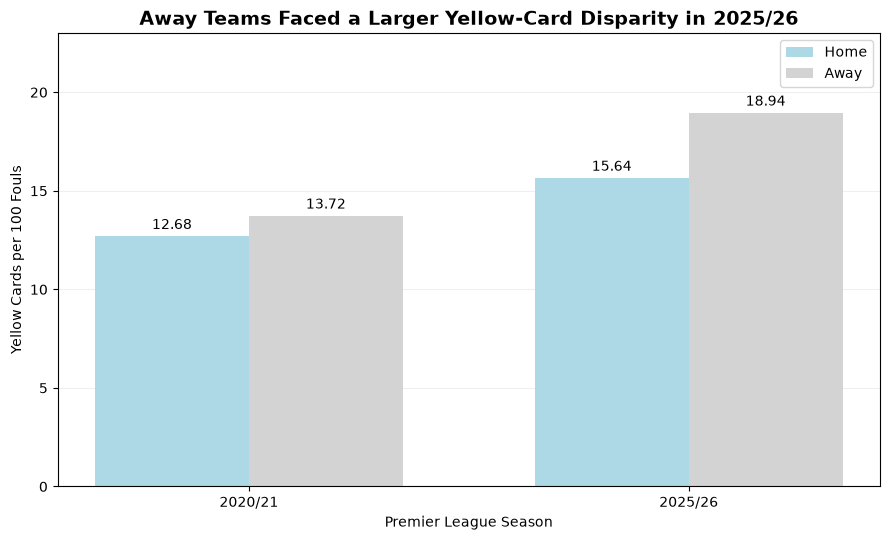

In [24]:
# Step 14: Final Visualization for Finding 4

import os 
import matplotlib.pyplot as plt
import numpy as np

seasons = ["2020/21", "2025/26"]

home_rates = [home_rate_2020 * 100, home_rate * 100]
away_rates = [away_rate_2020 * 100, away_rate * 100]

x = np.arange(len(seasons))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

bars_home = ax.bar(
    x - width/2, home_rates, width,
    label="Home", color="lightblue"
)

bars_away = ax.bar(
    x + width/2, away_rates, width,
    label="Away", color="lightgrey"
)

ax.set_title("Away Teams Faced a Larger Yellow-Card Disparity in 2025/26",
             fontsize=14, fontweight="bold"
            )

ax.set_ylabel("Yellow Cards per 100 Fouls")
ax.set_xlabel("Premier League Season")
ax.set_xticks(x)
ax.set_xticklabels(seasons)
ax.set_ylim(0, 23)

ax.bar_label(bars_home, fmt="%.2f", padding=3)
ax.bar_label(bars_away, fmt="%.2f", padding=3)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)

plt.savefig("figures/finding-four.png", dpi=200, bbox_inches="tight")

plt.show()